In [1]:
import copy
import torch
import sys, os
sys.path.append(os.path.abspath(".."))

from model import EEGVAE


CKPT_ROOT = "/home/infres/yrothlin-24/EEG_Foundation_Model/outputs/pretraining"
MODEL_CHECKPOINTS = {
    name: f"{CKPT_ROOT}/{name}/pretraining_best.pt"
    for name in ["2_quantizers", "4_quantizers", "8_quantizers", "z_256", "z_128", "z_64"]
}

model_config = {
    "in_channels": 19,
    "out_channels": 19,
    "adaptor_layers": 4,
    "z_channels": 64,
    "ch": 64,
    "ch_mult": [1, 2, 4, 8],
    "n_blocks": 2,
    "dropout": 0.0,
    "mode": "vq",
    "num_embeddings": 256,
    "n_quantizers": 8,
    "commitment_cost": 0.25,
    "decay": 0.99,
}


def infer_vq_params(state_dict):
    """Infère (z_channels, n_quantizers) depuis les embeddings du quantizer."""
    prefix = "autoencoder.posterior.quantize"

    # ResidualVectorQuantizer : quantize.quantizers.{i}.embedding
    q_indices, z_channels = set(), None
    for key, tensor in state_dict.items():
        if key.startswith(f"{prefix}.quantizers.") and key.endswith(".embedding"):
            idx = int(key.split(".quantizers.")[1].split(".")[0])
            q_indices.add(idx)
            z_channels = tensor.shape[1]          # (num_embeddings, z_channels)
    if q_indices:
        return z_channels, len(q_indices)

    # VectorQuantizerEMA (n_quantizers == 1) : quantize.embedding
    emb = state_dict.get(f"{prefix}.embedding")
    if emb is not None:
        return emb.shape[1], 1

    raise KeyError("Impossible d'inférer z_channels / n_quantizers (mode 'vq' attendu).")


def load_pretrained_model(model_config, checkpoint_path, device="cpu"):
    """Adapte la config au checkpoint, construit le modèle et charge les poids."""
    checkpoint = torch.load(checkpoint_path, map_location="cpu")
    state_dict = checkpoint["model"]

    z_channels, n_quantizers = infer_vq_params(state_dict)

    config = copy.deepcopy(model_config)
    config["z_channels"] = z_channels
    config["n_quantizers"] = n_quantizers

    model = EEGVAE(**config)
    model.load_state_dict(state_dict)
    model.to(device)
    model.eval()

    print(f"[LOAD] {os.path.basename(os.path.dirname(checkpoint_path)):<14} "
          f"-> z_channels={z_channels}, n_quantizers={n_quantizers}")
    return model, config


device = "cuda" if torch.cuda.is_available() else "cpu"

# Chargement de tous les checkpoints pré-entraînés (config adaptée automatiquement)
models, configs = {}, {}
for name, path in MODEL_CHECKPOINTS.items():
    models[name], configs[name] = load_pretrained_model(model_config, path, device)


/home/infres/yrothlin-24/.local/share/mamba/envs/rech202/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


[LOAD] 2_quantizers   -> z_channels=512, n_quantizers=2
[LOAD] 4_quantizers   -> z_channels=512, n_quantizers=4
[LOAD] 8_quantizers   -> z_channels=512, n_quantizers=8
[LOAD] z_256          -> z_channels=256, n_quantizers=8
[LOAD] z_128          -> z_channels=128, n_quantizers=8
[LOAD] z_64           -> z_channels=64, n_quantizers=8


In [2]:
from eeg_preprocessing.loaders import build_loaders


datasets = {
    "PHYSIONETMI": {
        "dataset_path": "/projects/EEG-foundation-model/RECH202/tests_2/PHYSIONETMI/physionetmi.lmdb",
        "n_classes": 4,
        "num_channels": 64,
    },
    "SLEEPEDFX": {
        "dataset_path": "/projects/EEG-foundation-model/RECH202/tests_2/SLEEPEDF/sleepedf.lmdb",
        "n_classes": 5,
        "num_channels": 2,
        "class_weights": [0.54, 1.88, 1.09, 2.86, 1.83],
    },
    "SEEDV": {
        "dataset_path": "/projects/EEG-foundation-model/RECH202/tests_2/SEEDV/seedv.lmdb",
        "num_channels": 62,
        "n_classes": 5,
    },
    "BCI2A": {
        "dataset_path": "/projects/EEG-foundation-model/RECH202/tests_2/BCI2A/bci2a.lmdb",
        "num_channels": 22,
        "n_classes": 4,
    },
    "TUAB": {
        "dataset_path": "/projects/EEG-foundation-model/RECH202/tests_2/TUAB/tuab.lmdb",
        "n_classes": 2,
    },
    "FACED": {
        "dataset_path": "/projects/EEG-foundation-model/RECH202/tests_2/FACED/faced.lmdb",
        "n_classes": 9,
    },
    "KARAONE": {
        "dataset_path": "/projects/EEG-foundation-model/RECH202/tests_2/KARAONE/karaone.lmdb",
        "n_classes": 11,
    },
    "BCI2020": {
        "dataset_path": "/projects/EEG-foundation-model/RECH202/tests_2/BCI2020/bci2020.lmdb",
        "n_classes": 5,
    },
    "CHISCO": {
        "dataset_path": "/projects/EEG-foundation-model/RECH202/tests_2/CHISCO/chisco.lmdb",
        "n_classes": 39,
    },
    "SIENA": {
        "dataset_path": "/projects/EEG-foundation-model/RECH202/tests_2/SIENA/siena.lmdb",
        "n_classes": 2,
    },
    "SHUMI": {
        "dataset_path": "/projects/EEG-foundation-model/RECH202/tests_2/SHUMI/shumi.lmdb",
        "n_classes": 2,
    },
}

data_config = {
  'batch_size': 128,
  'split_ratio': [0.8, 0.1, 0.1],
  'num_workers': 4,
  'pin_memory': True,
  'persistent_workers': False,
  'seed': 100,
  'channel_mode': "mapped",
  'return_ch_names': False,
  'scale_factor': 100000
}

dataset = "PHYSIONETMI"
lmdb_path = datasets[dataset]["dataset_path"]


train_loader, val_loader, test_loader = build_loaders(
        lmdb_path=lmdb_path,
        split_ratio=data_config["split_ratio"],
        batch_size=data_config["batch_size"],
        seed=data_config["seed"],
        num_workers=data_config["num_workers"],
        pin_memory=data_config["pin_memory"],
        persistent_workers=data_config["persistent_workers"],
        channel_mode=data_config["channel_mode"],
        return_ch_names=data_config["return_ch_names"],
        # scale_factor=data_config["scale_factor"]
    )    


print(f"Train loader length: {len(train_loader)}")
print(f"Validation loader length: {len(val_loader)}")
print(f"Test loader length: {len(test_loader)}")


[LOADER] Total subjects: 109
[LOADER] Split source: ratio
[LOADER] Train subjects: 87 | ['S010', 'S066', 'S076', 'S003', 'S018', 'S100', 'S087', 'S055', 'S068', 'S097', 'S057', 'S098', 'S012', 'S081', 'S013', 'S047', 'S006', 'S095', 'S062', 'S005', 'S037', 'S044', 'S080', 'S017', 'S014', 'S058', 'S084', 'S078', 'S032', 'S008', 'S063', 'S028', 'S020', 'S092', 'S050', 'S026', 'S031', 'S070', 'S035', 'S042', 'S093', 'S064', 'S038', 'S067', 'S033', 'S079', 'S046', 'S061', 'S039', 'S004', 'S073', 'S074', 'S086', 'S009', 'S106', 'S041', 'S077', 'S029', 'S071', 'S088', 'S102', 'S002', 'S054', 'S022', 'S082', 'S075', 'S090', 'S103', 'S001', 'S024', 'S096', 'S021', 'S049', 'S036', 'S072', 'S060', 'S052', 'S104', 'S053', 'S048', 'S101', 'S025', 'S109', 'S105', 'S089', 'S040', 'S030']
[LOADER] Validation subjects: 11 | ['S043', 'S027', 'S083', 'S085', 'S007', 'S034', 'S107', 'S011', 'S016', 'S069', 'S015']
[LOADER] Test subjects: 11 | ['S065', 'S056', 'S045', 'S094', 'S051', 'S091', 'S023', 'S099

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import mne
from scipy.spatial.distance import squareform, pdist
from scipy.stats import spearmanr

mne.set_log_level("ERROR")

TARGET_CHS = ["FP1", "FP2", "F3", "F4", "C3", "C4", "P3", "P4", "O1", "O2",
              "F7", "F8", "T7", "T8", "P7", "P8", "FZ", "CZ", "PZ"]
N_CH = len(TARGET_CHS)

montage = mne.channels.make_standard_montage("standard_1020")
pos = montage.get_positions()["ch_pos"]
lut = {k.upper(): k for k in pos}
MNE_NAMES = [lut[ch.upper()] for ch in TARGET_CHS]
XYZ = np.array([pos[n] for n in MNE_NAMES])
PHYS_DIST = squareform(pdist(XYZ))
INFO = mne.create_info(MNE_NAMES, sfreq=100.0, ch_types="eeg")
INFO.set_montage(montage)
_TRIU = np.triu_indices(N_CH, k=1)


def topomap(values, ax, title, cmap="RdBu_r", names=TARGET_CHS, sphere=0.11):
    im, _ = mne.viz.plot_topomap(np.asarray(values), INFO, axes=ax, show=False,
                                 cmap=cmap, contours=4, sensors=True, names=names,
                                 extrapolate="head", sphere=sphere)
    ax.set_title(title, fontsize=9)
    return im


def mantel_test(relation, n_perm=2000, seed=0):
    rel = np.asarray(relation)
    r_obs = spearmanr(rel[_TRIU], PHYS_DIST[_TRIU]).statistic
    rng = np.random.default_rng(seed)
    count = 0
    for _ in range(n_perm):
        p = rng.permutation(N_CH)
        rp = rel[np.ix_(p, p)]
        if abs(spearmanr(rp[_TRIU], PHYS_DIST[_TRIU]).statistic) >= abs(r_obs):
            count += 1
    return r_obs, (count + 1) / (n_perm + 1)


modèle              rho        p
2_quantizers     -0.711   0.0005
4_quantizers     -0.789   0.0005
8_quantizers     -0.737   0.0005
z_256            -0.801   0.0005
z_128            -0.744   0.0005
z_64             -0.758   0.0005


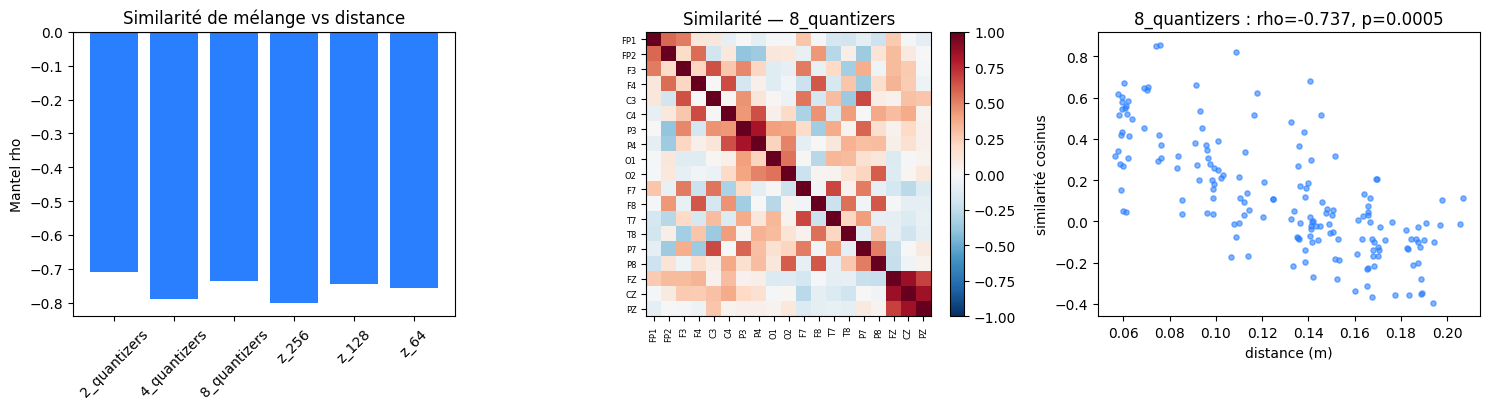

In [4]:
def adaptor_channel_similarity(model):
    W = model.channel_adaptor.model[0].weight.detach().cpu().numpy()[..., 0]
    Wn = W / (np.linalg.norm(W, axis=0, keepdims=True) + 1e-8)
    return Wn.T @ Wn


results_intrinsic = {}
print(f"{'modèle':<14} {'rho':>8} {'p':>8}")
for name, model in models.items():
    S = adaptor_channel_similarity(model)
    rho, p = mantel_test(S)
    results_intrinsic[name] = (S, rho, p)
    print(f"{name:<14} {rho:>+8.3f} {p:>8.4f}")

REF = "8_quantizers"
S_ref, rho_ref, p_ref = results_intrinsic[REF]

fig = plt.figure(figsize=(15, 4.2))

ax1 = fig.add_subplot(1, 3, 1)
names = list(results_intrinsic)
rhos = [results_intrinsic[n][1] for n in names]
colors = ["#2a7fff" if results_intrinsic[n][2] < 0.05 else "#bbbbbb" for n in names]
ax1.bar(names, rhos, color=colors)
ax1.axhline(0, color="k", lw=0.8)
ax1.set_ylabel("Mantel rho")
ax1.set_title("Similarité de mélange vs distance")
ax1.tick_params(axis="x", rotation=45)

ax2 = fig.add_subplot(1, 3, 2)
im = ax2.imshow(S_ref, cmap="RdBu_r", vmin=-1, vmax=1)
ax2.set_xticks(range(N_CH)); ax2.set_xticklabels(TARGET_CHS, rotation=90, fontsize=6)
ax2.set_yticks(range(N_CH)); ax2.set_yticklabels(TARGET_CHS, fontsize=6)
ax2.set_title(f"Similarité — {REF}")
fig.colorbar(im, ax=ax2, fraction=0.046)

ax3 = fig.add_subplot(1, 3, 3)
ax3.scatter(PHYS_DIST[_TRIU], S_ref[_TRIU], s=14, alpha=0.6, color="#2a7fff")
ax3.set_xlabel("distance (m)")
ax3.set_ylabel("similarité cosinus")
ax3.set_title(f"{REF} : rho={rho_ref:+.3f}, p={p_ref:.4f}")

plt.tight_layout()
plt.show()


occlusion 8_quantizers | 512 trials | rho=+0.034 p=0.6057


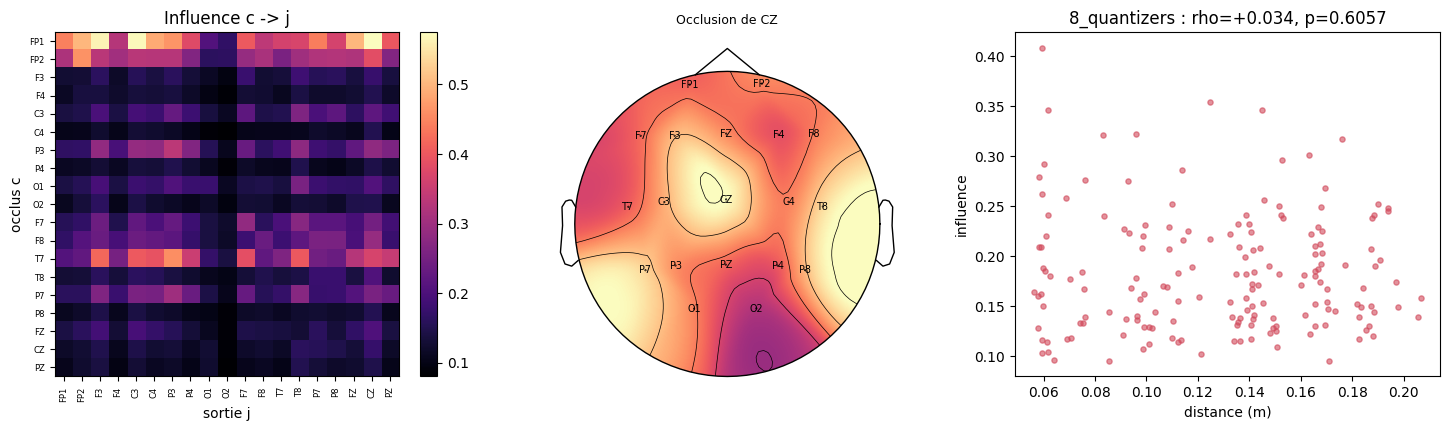

In [5]:
import torch

REF_MODEL = "8_quantizers"
N_BATCHES = 4
model = models[REF_MODEL]

batches = []
for i, (x, _) in enumerate(test_loader):
    batches.append(x.to(device))
    if i + 1 >= N_BATCHES:
        break

influence = np.zeros((N_CH, N_CH))
n_seen = 0
model.eval()
with torch.no_grad():
    for x in batches:
        rec_base = model.reconstruct(x)
        for c in range(N_CH):
            x_occ = x.clone()
            x_occ[:, c, :] = 0.0
            delta = (model.reconstruct(x_occ) - rec_base).pow(2).mean(dim=(0, 2)).sqrt()
            influence[c] += delta.cpu().numpy() * x.shape[0]
        n_seen += x.shape[0]
influence /= n_seen

infl_sym = 0.5 * (influence + influence.T)
rho_f, p_f = mantel_test(infl_sym)
print(f"occlusion {REF_MODEL} | {n_seen} trials | rho={rho_f:+.3f} p={p_f:.4f}")

SEED = "CZ"
seed_idx = TARGET_CHS.index(SEED)

fig = plt.figure(figsize=(15, 4.4))

ax1 = fig.add_subplot(1, 3, 1)
im = ax1.imshow(influence, cmap="magma")
ax1.set_xlabel("sortie j"); ax1.set_ylabel("occlus c")
ax1.set_xticks(range(N_CH)); ax1.set_xticklabels(TARGET_CHS, rotation=90, fontsize=6)
ax1.set_yticks(range(N_CH)); ax1.set_yticklabels(TARGET_CHS, fontsize=6)
ax1.set_title("Influence c -> j")
fig.colorbar(im, ax=ax1, fraction=0.046)

ax2 = fig.add_subplot(1, 3, 2)
topomap(influence[seed_idx], ax2, f"Occlusion de {SEED}", cmap="magma")

ax3 = fig.add_subplot(1, 3, 3)
ax3.scatter(PHYS_DIST[_TRIU], infl_sym[_TRIU], s=14, alpha=0.6, color="#d1495b")
ax3.set_xlabel("distance (m)")
ax3.set_ylabel("influence")
ax3.set_title(f"{REF_MODEL} : rho={rho_f:+.3f}, p={p_f:.4f}")

plt.tight_layout()
plt.show()


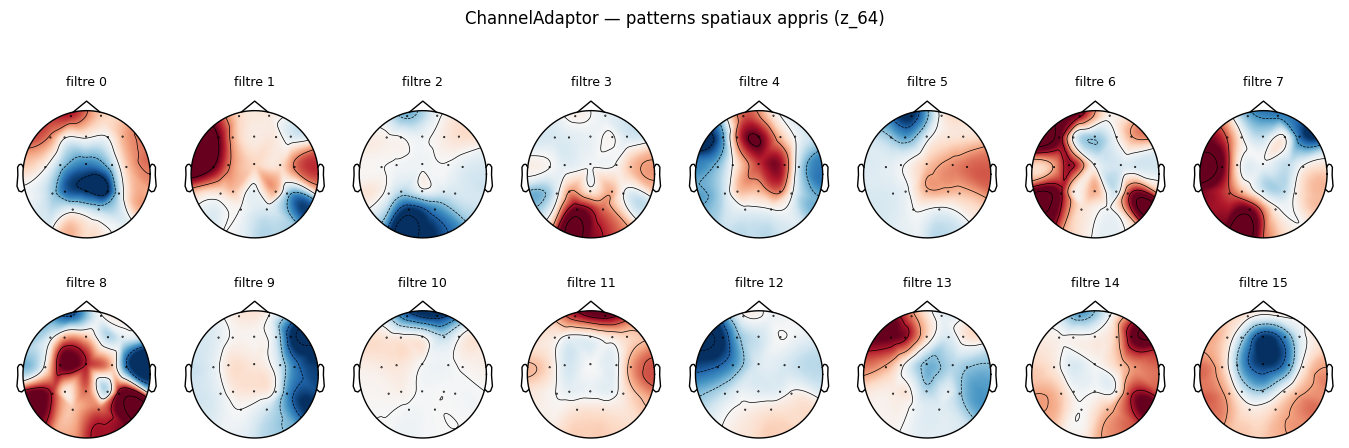

In [6]:
REF = "z_64"
W = models[REF].channel_adaptor.model[0].weight.detach().cpu().numpy()[..., 0]

n_filters = W.shape[0]
cols = (n_filters + 1) // 2
fig, axes = plt.subplots(2, cols, figsize=(1.7 * cols, 5))
for i, ax in enumerate(axes.ravel()):
    if i < n_filters:
        topomap(W[i] / (np.abs(W[i]).max() + 1e-8), ax, f"filtre {i}", names=None)
    else:
        ax.axis("off")
fig.suptitle(f"ChannelAdaptor — patterns spatiaux appris ({REF})")
plt.tight_layout()
plt.show()


z1 == W @ x  (erreur max = 8.7e-11)


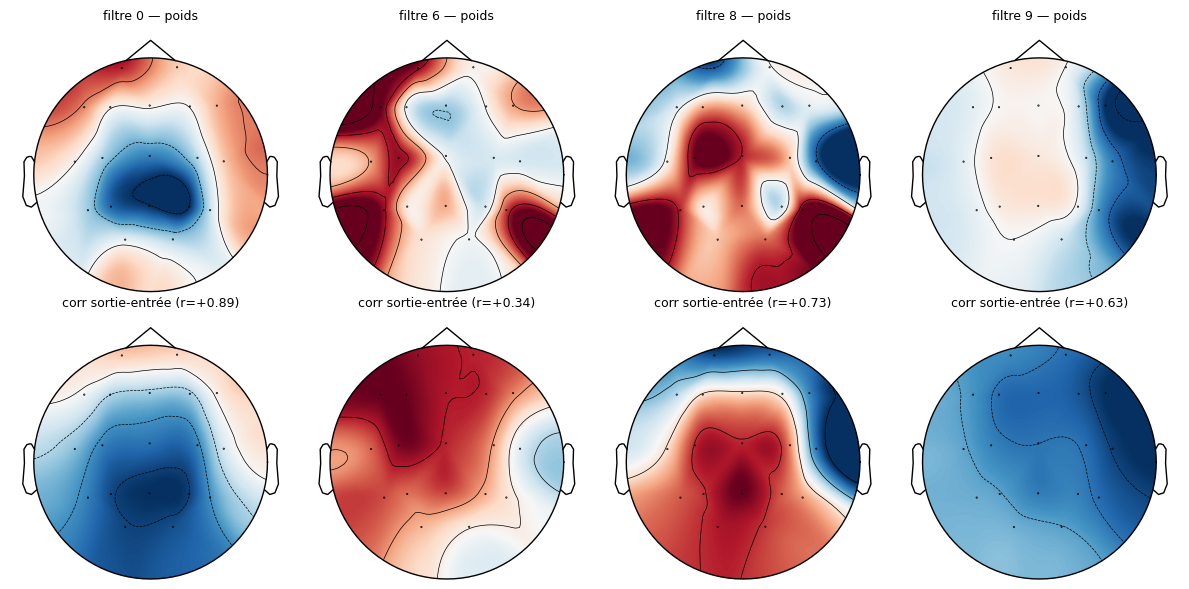

In [7]:
import torch

FILTERS = [0, 6, 8, 9]

x = next(iter(test_loader))[0].to(device)
conv0 = models[REF].channel_adaptor.model[0]
with torch.no_grad():
    z1 = conv0(x)
W = conv0.weight[..., 0].detach().cpu().numpy()

z1_manual = torch.einsum("oe,bet->bot", conv0.weight[..., 0], x)
print(f"z1 == W @ x  (erreur max = {(z1 - z1_manual).abs().max().item():.1e})")

n_out = W.shape[0]
xf = x.permute(1, 0, 2).reshape(N_CH, -1).cpu().numpy()
zf = z1.permute(1, 0, 2).reshape(n_out, -1).cpu().numpy()
R = np.corrcoef(np.vstack([zf, xf]))[:n_out, n_out:]

fig, axes = plt.subplots(2, len(FILTERS), figsize=(3 * len(FILTERS), 6))
for col, i in enumerate(FILTERS):
    r = np.corrcoef(R[i], W[i])[0, 1]
    topomap(W[i] / (np.abs(W[i]).max() + 1e-8), axes[0, col], f"filtre {i} — poids", names=None)
    topomap(R[i], axes[1, col], f"corr sortie-entrée (r={r:+.2f})", names=None)
plt.tight_layout()
plt.show()


In [8]:
import pandas as pd

FRONT = ["FP1", "FP2", "F3", "F4", "F7", "F8", "FZ"]
POST = ["P3", "P4", "P7", "P8", "PZ", "O1", "O2"]
LEFT = ["FP1", "F3", "F7", "C3", "T7", "P3", "P7", "O1"]
RIGHT = ["FP2", "F4", "F8", "C4", "T8", "P4", "P8", "O2"]
region = lambda g: [TARGET_CHS.index(c) for c in g]


def interpret(w):
    w = w / (np.linalg.norm(w) + 1e-8)
    ap = w[region(FRONT)].mean() - w[region(POST)].mean()
    lr = w[region(LEFT)].mean() - w[region(RIGHT)].mean()
    a = np.abs(w)
    if a.max() / a.sum() > 0.30:
        return f"focal {TARGET_CHS[a.argmax()]}"
    lab_ap = "frontal+/postérieur-" if ap > 0 else "postérieur+/frontal-"
    lab_lr = "gauche+/droite-" if lr > 0 else "droite+/gauche-"
    (prim, lp), (sec, ls) = sorted([(lab_ap, abs(ap)), (lab_lr, abs(lr))], key=lambda t: -t[1])
    return prim if ls < 0.6 * lp else f"{prim} + {sec}"


rows = []
for i in range(len(W)):
    r = np.corrcoef(R[i], W[i])[0, 1]
    top = [f"{TARGET_CHS[j]}({R[i, j]:+.2f})" for j in np.argsort(np.abs(R[i]))[::-1][:3]]
    rows.append({
        "filtre": i,
        "interprétation": interpret(W[i]),
        "corr": round(float(r), 2),
        "électrodes dominantes": ", ".join(top),
    })

table = pd.DataFrame(rows)
table


,filtre,interprétation,corr,électrodes dominantes
0,0,frontal+/postérieur-,0.89,"PZ(-0.80), P4(-0.75), O1(-0.74)"
1,1,gauche+/droite-,0.55,"F3(+0.88), C3(+0.85), F7(+0.85)"
2,2,frontal+/postérieur-,0.55,"O1(-0.89), PZ(-0.87), O2(-0.83)"
3,3,postérieur+/frontal-,0.72,"O1(+0.93), O2(+0.87), PZ(+0.81)"
4,4,frontal+/postérieur- + droite+/gauche-,0.77,"FZ(+0.92), F4(+0.90), CZ(+0.88)"
5,5,droite+/gauche- + postérieur+/frontal-,0.73,"FP1(-0.80), FP2(-0.66), F7(-0.60)"
6,6,gauche+/droite-,0.34,"F7(+0.84), F3(+0.83), C3(+0.81)"
7,7,gauche+/droite- + postérieur+/frontal-,0.79,"FP2(-0.56), O1(+0.51), F8(-0.51)"
8,8,postérieur+/frontal-,0.73,"PZ(+0.86), O1(+0.78), CZ(+0.76)"
9,9,gauche+/droite-,0.63,"F8(-0.82), T8(-0.76), F4(-0.70)"


64 canaux de sortie | 17 morts (ReLU)


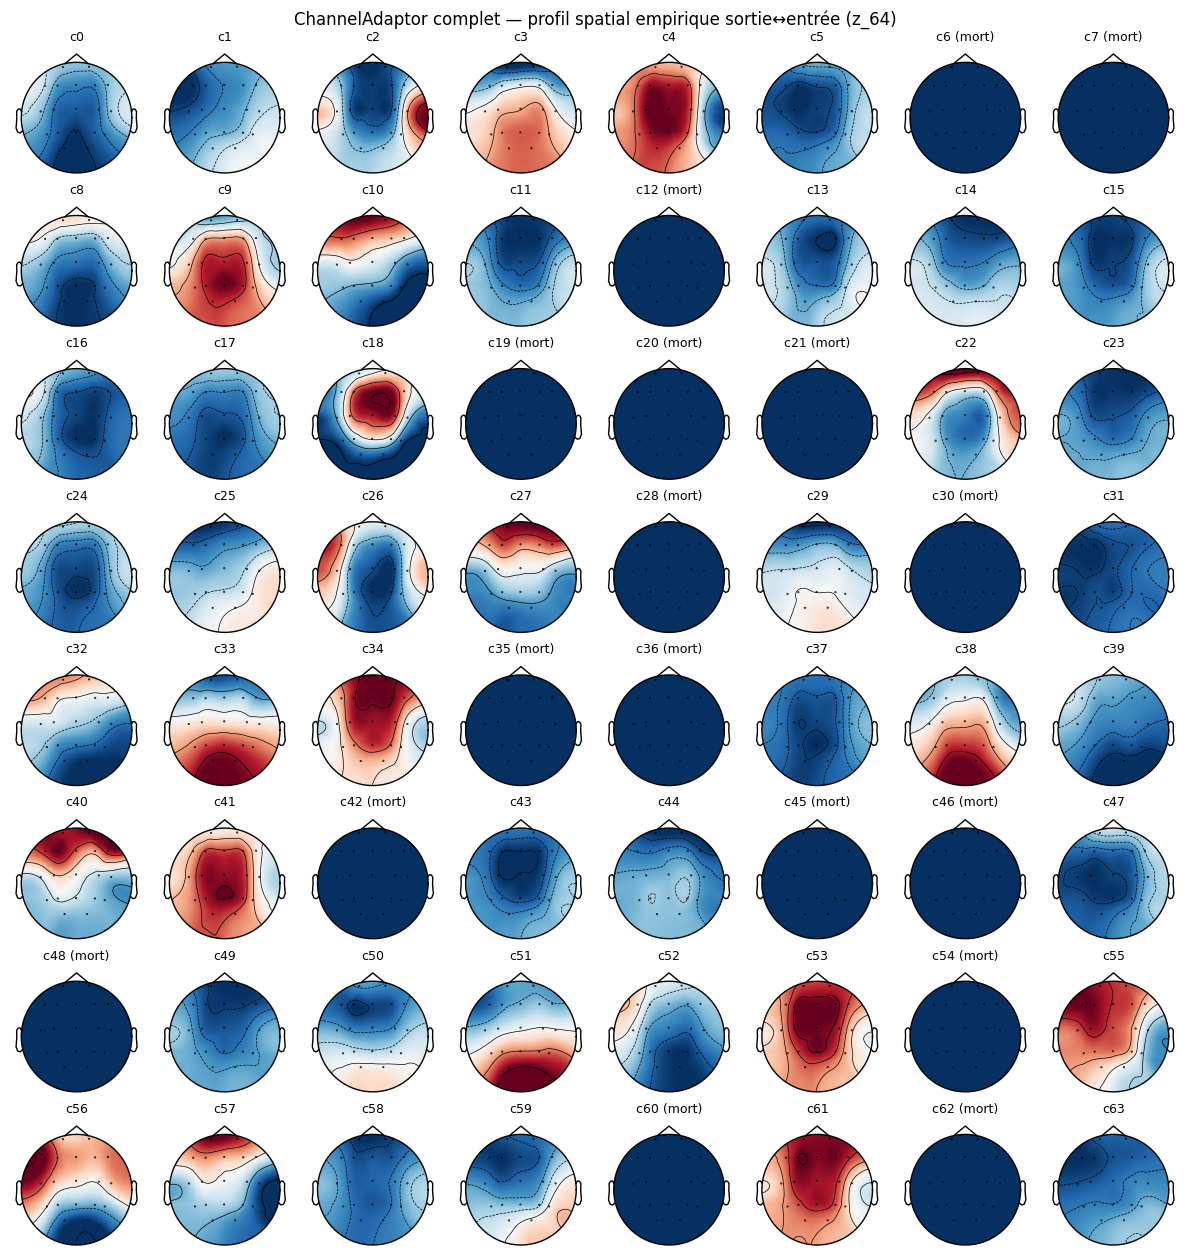

In [9]:
x = next(iter(test_loader))[0].to(device)
with torch.no_grad():
    z_full = models[REF].channel_adaptor(x)

n_out = z_full.shape[1]
xf = x.permute(1, 0, 2).reshape(N_CH, -1).cpu().numpy()
zf = z_full.permute(1, 0, 2).reshape(n_out, -1).cpu().numpy()

Zc = zf - zf.mean(1, keepdims=True)
Xc = xf - xf.mean(1, keepdims=True)
den = np.linalg.norm(Zc, axis=1)[:, None] * np.linalg.norm(Xc, axis=1)[None, :]
R_full = (Zc @ Xc.T) / (den + 1e-12)

alive = zf.std(1) > 1e-8
print(f"{n_out} canaux de sortie | {(~alive).sum()} morts (ReLU)")

cols = 8
n_rows = int(np.ceil(n_out / cols))
fig, axes = plt.subplots(n_rows, cols, figsize=(1.5 * cols, 1.6 * n_rows))
for ax, i in zip(axes.ravel(), range(n_out)):
    tag = f"c{i}" if alive[i] else f"c{i} (mort)"
    topomap(R_full[i], ax, tag, names=None)
for ax in axes.ravel()[n_out:]:
    ax.axis("off")
fig.suptitle(f"ChannelAdaptor complet — profil spatial empirique sortie↔entrée ({REF})")
plt.tight_layout()
plt.show()


[LOADER] Total subjects: 9
[LOADER] Split source: ratio
[LOADER] Train subjects: 7 | ['A05', 'A01', 'A06', 'A09', 'A07', 'A02', 'A04']
[LOADER] Validation subjects: 1 | ['A08']
[LOADER] Test subjects: 1 | ['A03']


BCI2A | accuracy=0.422 | balanced_acc=0.423 | f1_macro=0.408

  CZ  +0.074
  C4  +0.029
  PZ  +0.011
 FP1  +0.000
 FP2  +0.000
  O1  +0.000
  O2  +0.000
  F7  +0.000
  F8  +0.000
  T7  +0.000
  T8  +0.000
  P7  +0.000
  P8  +0.000
  F4  -0.002
  P3  -0.002
  FZ  -0.006
  F3  -0.018
  C3  -0.020
  P4  -0.020


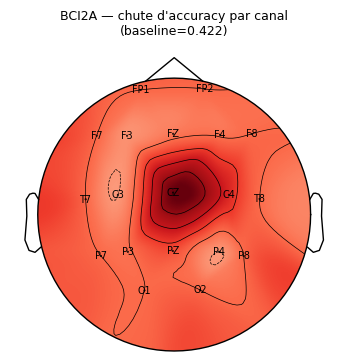

In [10]:
import torch
from model import DownstreamModel
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score

DS_DATASET = "BCI2A"
DS_CKPT = "/home/infres/yrothlin-24/EEG_Foundation_Model/outputs/downstream/tests/downstream_best.pt"
NUM_CLASSES = datasets[DS_DATASET]["n_classes"]

ds_train, ds_val, ds_test = build_loaders(
    lmdb_path=datasets[DS_DATASET]["dataset_path"],
    split_ratio=data_config["split_ratio"],
    batch_size=data_config["batch_size"],
    seed=data_config["seed"],
    num_workers=data_config["num_workers"],
    pin_memory=data_config["pin_memory"],
    persistent_workers=data_config["persistent_workers"],
    channel_mode=data_config["channel_mode"],
    return_ch_names=data_config["return_ch_names"],
)

clf = DownstreamModel(
    backbone_config=configs["z_64"],
    num_classes=NUM_CLASSES,
    freeze_backbone=True,
    freeze_channel_adaptor=True,
    probe="linear",
    probe_config={"pooling": "none"},
).to(device).eval()

with torch.no_grad():
    clf(next(iter(ds_test))[0].to(device))
clf.load_state_dict(torch.load(DS_CKPT, map_location=device)["model"])


@torch.no_grad()
def predict(loader, ablate=None):
    y_true, y_pred = [], []
    for x, y in loader:
        x = x.to(device)
        if ablate is not None:
            x = x.clone()
            x[:, ablate, :] = 0.0
        y_pred.append(clf(x).argmax(1).cpu())
        y_true.append(y)
    return torch.cat(y_true), torch.cat(y_pred)


yt, yp = predict(ds_test)
acc = accuracy_score(yt, yp)
bacc = balanced_accuracy_score(yt, yp)
f1 = f1_score(yt, yp, average="macro")
print(f"{DS_DATASET} | accuracy={acc:.3f} | balanced_acc={bacc:.3f} | f1_macro={f1:.3f}")

importance = np.array([acc - accuracy_score(*predict(ds_test, ablate=c)) for c in range(N_CH)])

print()
for ch, imp in sorted(zip(TARGET_CHS, importance), key=lambda t: -t[1]):
    print(f"{ch:>4}  {imp:+.3f}")

fig, ax = plt.subplots(figsize=(4.5, 4))
topomap(importance, ax, f"{DS_DATASET} — chute d'accuracy par canal\n(baseline={acc:.3f})", cmap="Reds")
plt.show()
